# GPT-6.1 Terra Zero-Shot Evaluation

## 1. Model & Experiment Overview

GPT-6.1 Terra, recorded as `gpt-6.1-terra`, classified math word problems as `ANSWERABLE` or `UNANSWERABLE` using the original frozen zero-shot prompt. The experiments used OpenAI's hosted Chat Completions API. The model runtime was provider-managed, so local GPU, dtype, and tokenizer settings do not apply.

This notebook reads the completed `run_01` artifacts for SUM Test, UMWP and MATE under `results/api/openai/gpt-6.1-terra/`. The analysis uses the saved metrics, predictions, confusion matrices, and API usage metadata.

SUM Test is the internal held-out split. UMWP and MATE are external benchmarks.

In [1]:
import hashlib
import json
import math
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

PROJECT_ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / 'notebooks').is_dir() and (path / 'results/api/openai').is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Start from the CDS1092 project root or notebooks directory.')

RESULTS_DIR = PROJECT_ROOT / 'results/api/openai/gpt-6.1-terra'
RUN_ID = 'run_01'
LABELS = ['ANSWERABLE', 'UNANSWERABLE']
PREDICTED_LABELS = [*LABELS, 'INVALID']
METRICS = {
    'Accuracy': 'accuracy',
    'Precision (UNANSWERABLE)': 'precision_unanswerable',
    'Recall (UNANSWERABLE)': 'recall_unanswerable',
    'F1 (UNANSWERABLE)': 'f1_unanswerable',
}
plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})


def load_evaluation(dataset, expected_examples, identifier):
    directory = RESULTS_DIR / dataset / RUN_ID
    metrics = json.loads((directory / 'metrics.json').read_text(encoding='utf-8'))
    matrix = pd.read_csv(directory / 'confusion_matrix.csv', index_col='true_label')
    run = metrics['run']
    metadata = json.loads((directory / 'run_metadata.json').read_text(encoding='utf-8'))
    if (not metadata['all_rows_received'] or run['limit'] is not None
            or any(metadata[key] != value for key, value in run.items())):
        raise ValueError(f'{directory}: incomplete run or inconsistent metadata')
    if hashlib.sha256(run['prompt'].encode('utf-8')).hexdigest() != run['prompt_sha256']:
        raise ValueError(f'{directory}: saved prompt fingerprint does not match')
    path = PROJECT_ROOT / 'data/processed' / dataset / 'test.csv'
    fingerprint = hashlib.sha256(path.read_bytes().replace(b'\r\n', b'\n')).hexdigest()
    if run['dataset_sha256'] != fingerprint:
        raise ValueError(f'{directory}: benchmark fingerprint differs')
    benchmark = pd.read_csv(path, keep_default_na=False, dtype=str)
    usage = metadata['usage']
    if (usage['completed_requests'] != expected_examples
            or sum(usage['attempts_by_state'].values()) != usage['request_attempts']
            or sum(usage['finish_reasons'].values()) != usage['completed_requests']
            or usage['input_tokens'] + usage['output_tokens'] != usage['total_tokens']):
        raise ValueError(f'{directory}: inconsistent request or token totals')
    rates = metadata['prices_usd_per_million']
    cached = usage['cached_input_tokens']
    if not 0 <= cached <= usage['input_tokens']:
        raise ValueError(f'{directory}: cached input tokens are out of range')
    estimated = ((usage['input_tokens'] - cached) * rates['input']
                 + cached * rates['cached_input'] + usage['output_tokens'] * rates['output']) / 1_000_000
    if usage['estimated_cost_usd'] is None or not math.isclose(
            usage['estimated_cost_usd'], estimated, rel_tol=0, abs_tol=1e-10):
        raise ValueError(f'{directory}: token usage and estimated cost disagree')
    predictions = pd.read_csv(
        directory / 'predictions.csv', keep_default_na=False,
        dtype={**{field: str for field in benchmark.columns}, 'raw_response': str},
    )
    expected_columns = {'row_index', identifier, 'text', 'true_label',
                        'raw_response', 'prediction', 'valid', 'hit_token_limit'}
    if not expected_columns.issubset(predictions):
        raise ValueError(f'{directory}: predictions CSV lacks required columns')
    if (predictions['row_index'].tolist() != list(range(expected_examples))
            or predictions[identifier].eq('').any()
            or not predictions['true_label'].isin(LABELS).all()
            or not predictions['prediction'].isin(PREDICTED_LABELS).all()
            or not predictions['valid'].eq(predictions['prediction'].ne('INVALID')).all()
            or predictions['hit_token_limit'].sum() != usage['finish_reasons'].get('length', 0)):
        raise ValueError(f'{directory}: unexpected prediction rows or labels')
    # SUM identifies pairs. The external benchmarks identify individual questions.
    if identifier == 'id' and not predictions[identifier].is_unique:
        raise ValueError(f'{directory}: question IDs are not unique')
    aligned = benchmark.rename(columns={'label': 'true_label'})
    for field in aligned:
        saved = predictions[field].astype(str)
        gold = aligned[field]
        if field == 'text':
            saved = saved.str.replace('\r\n', '\n', regex=False)
            gold = gold.str.replace('\r\n', '\n', regex=False)
        if not saved.equals(gold):
            raise ValueError(f'{directory}: benchmark and predictions differ in {field}')
    parsed = predictions['raw_response'].str.strip()
    parsed = parsed.where(parsed.isin(LABELS), 'INVALID')
    if not parsed.eq(predictions['prediction']).all():
        raise ValueError(f'{directory}: raw responses and recorded labels disagree')
    reconstructed = pd.crosstab(predictions['true_label'], predictions['prediction']).reindex(
        index=LABELS, columns=PREDICTED_LABELS, fill_value=0,
    )
    if reconstructed.values.tolist() != matrix.values.tolist():
        raise ValueError(f'{directory}: prediction counts disagree with the matrix')

    if run['model_id'] != 'gpt-6.1-terra':
        raise ValueError(f'{directory}: unexpected model identity')
    if (run['dataset'], run['run_id'], metrics['positive_class']) != (dataset, RUN_ID, LABELS[1]):
        raise ValueError(f'{directory}: unexpected run identity or positive class')
    if (list(matrix.index) != LABELS or list(matrix.columns) != PREDICTED_LABELS
            or metrics['confusion_matrix_rows'] != LABELS
            or metrics['confusion_matrix_columns'] != PREDICTED_LABELS):
        raise ValueError(f'{directory}: unexpected matrix labels or order')
    if (not all(pd.api.types.is_integer_dtype(dtype) for dtype in matrix.dtypes)
            or (matrix < 0).any().any() or matrix.values.tolist() != metrics['confusion_matrix']):
        raise ValueError(f'{directory}: CSV and JSON confusion counts disagree or are invalid')
    if not (matrix.values.sum() == metrics['num_examples'] == run['row_count'] == expected_examples):
        raise ValueError(f'{directory}: unexpected number of examples')

    tn, fp, invalid_negative = matrix.loc[LABELS[0]]
    fn, tp, invalid_positive = matrix.loc[LABELS[1]]
    missed = fn + invalid_positive

    def ratio(numerator, denominator):
        return numerator / denominator if denominator else 0.0

    expected = {
        'accuracy': (tn + tp) / expected_examples,
        'precision_unanswerable': ratio(tp, tp + fp),
        'recall_unanswerable': ratio(tp, tp + missed),
        'f1_unanswerable': ratio(2 * tp, 2 * tp + fp + missed),
        'num_invalid': invalid_negative + invalid_positive,
        'invalid_rate': (invalid_negative + invalid_positive) / expected_examples,
    }
    for key, value in expected.items():
        if not math.isclose(metrics[key], value, rel_tol=0, abs_tol=1e-12):
            raise ValueError(f'{directory}: {key} disagrees with the saved confusion counts')
    return metrics, matrix, predictions, metadata


sum_metrics, sum_matrix, sum_predictions, sum_metadata = load_evaluation('sum', 10944, 'pair_id')
umwp_metrics, umwp_matrix, umwp_predictions, umwp_metadata = load_evaluation('umwp', 5200, 'id')
mate_metrics, mate_matrix, mate_predictions, mate_metadata = load_evaluation('mate', 9586, 'id')

In [2]:
run = sum_metadata
shared_settings = (
    'model_id', 'endpoint', 'openai_sdk_version', 'parameters', 'prompt_version', 'prompt',
    'prompt_sha256', 'invalid_output_policy', 'prices_usd_per_million', 'pricing_verified_date',
)
if any(run[key] != record[key] for record in (umwp_metadata, mate_metadata) for key in shared_settings):
    raise ValueError('Saved runs disagree on the shared API configuration.')

parameters = run['parameters']
configuration = {
    'Requested API model': run['model_id'],
    'Endpoint': run['endpoint'],
    'OpenAI SDK': run['openai_sdk_version'],
    'Prompt version': run['prompt_version'],
    'Reasoning effort': parameters['reasoning_effort'],
    'Temperature': parameters['temperature'],
    'Maximum completion tokens': parameters['max_completion_tokens'],
    'Service tier request': parameters['service_tier'],
    'API store parameter': parameters['store'],
}
display(pd.Series(configuration, name='Recorded setting').rename_axis('Setting').to_frame())
display(Markdown('**Exact prompt**\n\n```text\n' + run['prompt'] + '\n```'))

metadata = {'SUM Test': sum_metadata, 'UMWP': umwp_metadata, 'MATE': mate_metadata}
matrices = {'SUM Test': sum_matrix, 'UMWP': umwp_matrix, 'MATE': mate_matrix}
dataset_table = pd.DataFrame.from_dict({
    name: {
        'Examples': record['row_count'],
        **{label: f'{matrix.loc[label].sum():,} ({matrix.loc[label].sum() / record["row_count"]:.2%})'
           for label in LABELS},
        'Returned API model': ', '.join(record['usage']['returned_models']),
        'Started (UTC)': record['started_at_utc'],
    }
    for name, record in metadata.items() for matrix in [matrices[name]]
}, orient='index').rename_axis('Dataset')
display(dataset_table)

fingerprints = {
    'Prompt SHA-256': run['prompt_sha256'],
    **{f'{name} dataset SHA-256 ({record["run_id"]})': record['dataset_sha256']
       for name, record in metadata.items()},
}
display(pd.Series(fingerprints, name='Recorded value').rename_axis('Fingerprint').to_frame())

,Recorded setting
Setting,
Requested API model,gpt-6.1-terra
Endpoint,POST /v1/chat/completions
OpenAI SDK,2.54.0
Prompt version,original_frozen_zero_shot
Reasoning effort,none
Temperature,0
Maximum completion tokens,16
Service tier request,default
API store parameter,False


**Exact prompt**

```text
Determine whether the following math problem can be answered using the information provided.

Respond with exactly one label:
ANSWERABLE or UNANSWERABLE.

Do not solve the problem or provide an explanation.

Math problem:
{question}

Label:
```

,Examples,ANSWERABLE,UNANSWERABLE,Returned API model,Started (UTC)
Dataset,,,,,
SUM Test,10944,"5,472 (50.00%)","5,472 (50.00%)",gpt-6.1-terra,2026-11-22T11:13:50+00:00
UMWP,5200,"2,600 (50.00%)","2,600 (50.00%)",gpt-6.1-terra,2026-11-22T09:45:29+00:00
MATE,9586,"4,793 (50.00%)","4,793 (50.00%)",gpt-6.1-terra,2026-11-24T16:53:23+00:00


,Recorded value
Fingerprint,
Prompt SHA-256,0f38d949358979147c7d89f8c1e4635c9608de88a47fe2...
SUM Test dataset SHA-256 (run_01),c1e4bac1e1d1f27ab8a6408ac68ae710faf521822bff49...
UMWP dataset SHA-256 (run_01),92df3bed2d3cee139c6ddbca2673fca0a1687aa9f90b3c...
MATE dataset SHA-256 (run_01),377f7a28a6b2a5236ce24eeebc889c99ec38ff92c52c9b...


## 2. Evaluation Metrics

**UNANSWERABLE is the positive class.**

- **Accuracy** is the fraction of all questions assigned the correct label.
- **Precision** is the fraction of predicted UNANSWERABLE questions that are truly unanswerable.
- **Recall** is the fraction of truly unanswerable questions detected by the model.
- **F1** is the harmonic mean of precision and recall for UNANSWERABLE.

Confusion matrices show actual labels in rows and predicted labels in columns. A false positive flags an answerable question as unanswerable. A false negative marks an unanswerable question as answerable, which can lead a downstream solver to attempt a question with insufficient information. The INVALID column tracks responses outside the two permitted labels. Each heatmap scales its colors to its own counts.

The request used temperature zero to reduce sampling variability and reasoning effort `none`. The API's completion cap applies to hosted token counts. The saved CSV records the decoded text and uses JSON `null` for generated token IDs.

In [3]:
if any(sum_metrics['invalid_output_policy'] != m['invalid_output_policy'] for m in (umwp_metrics, mate_metrics)):
    raise ValueError('Saved runs disagree on the invalid-output policy')
display(Markdown('**Recorded scoring policy.** ' + sum_metrics['invalid_output_policy']))


def show_evaluation(name, metrics, matrix):
    summary = {
        'Examples': f"{metrics['num_examples']:,}",
        **{label: f'{metrics[key]:.2%}' for label, key in METRICS.items()},
        'Invalid outputs': f"{metrics['num_invalid']:,} ({metrics['invalid_rate']:.2%})",
    }
    display(pd.DataFrame([summary], index=pd.Index([name], name='Dataset')))

    fig, ax = plt.subplots(figsize=(6, 3.5), layout='constrained')
    values = matrix.to_numpy()
    limit = values.max()
    ax.imshow(values, cmap='Blues', vmin=0, vmax=limit, aspect='auto')
    for (row, column), value in matrix.stack().items():
        ax.text(matrix.columns.get_loc(column), matrix.index.get_loc(row), f'{value:,}',
                ha='center', va='center', color='white' if value > limit / 2 else 'black')
    ax.set_xticks(range(len(matrix.columns)), matrix.columns)
    ax.set_yticks(range(len(matrix.index)), matrix.index)
    ax.set(xlabel='Predicted label', ylabel='Actual label', title=f'{name} confusion matrix')
    plt.show()
    plt.close(fig)


def show_class_errors(matrix):
    support = matrix.sum(axis=1)
    correct = pd.Series([matrix.loc[label, label] for label in LABELS], index=LABELS)
    wrong_label = pd.Series(
        [matrix.loc[LABELS[0], LABELS[1]], matrix.loc[LABELS[1], LABELS[0]]],
        index=LABELS,
    )
    errors = pd.DataFrame({
        'Actual examples': support,
        'Correct': correct,
        'Wrong label': wrong_label,
        'INVALID': matrix['INVALID'],
        'Wrong-label rate': (wrong_label / support).map('{:.2%}'.format),
        'Total error rate': ((wrong_label + matrix['INVALID']) / support).map('{:.2%}'.format),
    })
    display(errors.rename_axis('Actual class'))


def interpret_errors(matrix):
    fp = matrix.loc['ANSWERABLE', 'UNANSWERABLE']
    fn = matrix.loc['UNANSWERABLE', 'ANSWERABLE']
    support = matrix.sum(axis=1)
    return (
        f'There were **{fp:,} false positives** ({fp / support["ANSWERABLE"]:.2%} '
        f'of answerable questions) and **{fn:,} false negatives** '
        f'({fn / support["UNANSWERABLE"]:.2%} of unanswerable questions). '
        f'Of the true UNANSWERABLE rows, {matrix.loc["UNANSWERABLE", "INVALID"]:,} '
        'additionally received INVALID responses and count as missed positives in recall.'
    )


def show_examples(predictions, identifier):
    false_positives = predictions['true_label'].eq('ANSWERABLE') & predictions['prediction'].eq('UNANSWERABLE')
    false_negatives = predictions['true_label'].eq('UNANSWERABLE') & predictions['prediction'].eq('ANSWERABLE')
    categories = {
        'False positive': false_positives,
        'False negative': false_negatives,
        'INVALID': predictions['prediction'].eq('INVALID'),
    }
    columns = ['row_index', identifier, 'text', 'true_label', 'prediction', 'raw_response', 'hit_token_limit']
    examples = pd.concat(
        [predictions.loc[mask, columns].head(1).assign(error=label) for label, mask in categories.items()],
        ignore_index=True,
    )
    # repr keeps empty strings, trailing whitespace and newlines visible.
    examples['raw_response'] = examples['raw_response'].map(repr)
    if examples.empty:
        display(Markdown('No recorded errors in these categories.'))
    else:
        display(examples.set_index('error').rename_axis('Error type').rename(columns={
            'row_index': 'Row index', 'pair_id': 'Pair ID', 'id': 'Question ID',
            'text': 'Question', 'true_label': 'Actual label', 'prediction': 'Prediction',
            'raw_response': 'Raw response (repr)', 'hit_token_limit': 'Hit token limit',
        }))
    missing = [label for label, mask in categories.items() if not mask.any()]
    if missing:
        display(Markdown('**Categories with no recorded examples:** ' + ', '.join(missing) + '.'))

**Recorded scoring policy.** After trimming surrounding whitespace, only exact uppercase labels are valid. INVALID is incorrect for accuracy and is a separate confusion-matrix column. INVALID on a true UNANSWERABLE row counts as a missed positive for recall and F1. Precision uses all predicted UNANSWERABLE rows. Zero denominators yield zero.

## 3. SUM Results & Analysis

SUM Test is the held-out split of the Synthetic Unanswerable Math benchmark. The analysis uses the complete saved test run.

The examples show the first recorded row in each error category, in evaluation order.

,Examples,Accuracy,Precision (UNANSWERABLE),Recall (UNANSWERABLE),F1 (UNANSWERABLE),Invalid outputs
Dataset,,,,,,
SUM Test,"10,944",86.04%,90.93%,80.06%,85.15%,0 (0.00%)


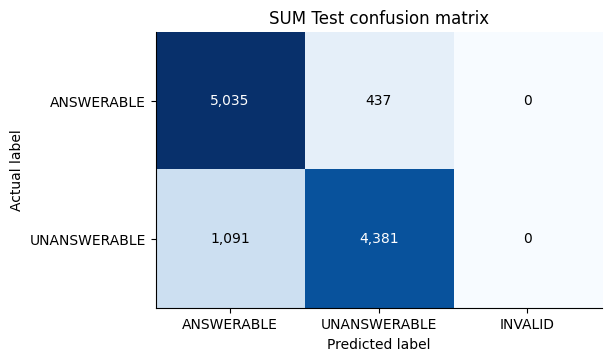

,Actual examples,Correct,Wrong label,INVALID,Wrong-label rate,Total error rate
Actual class,,,,,,
ANSWERABLE,5472,5035,437,0,7.99%,7.99%
UNANSWERABLE,5472,4381,1091,0,19.94%,19.94%


There were **437 false positives** (7.99% of answerable questions) and **1,091 false negatives** (19.94% of unanswerable questions). Of the true UNANSWERABLE rows, 0 additionally received INVALID responses and count as missed positives in recall.

,Row index,Pair ID,Question,Actual label,Prediction,Raw response (repr),Hit token limit
Error type,,,,,,,
False positive,16,6519,Two dice appear to be normal dice with their f...,ANSWERABLE,UNANSWERABLE,'UNANSWERABLE',False
False negative,6,13331,"Simplify first, then evaluate: \(\left(\frac{2...",UNANSWERABLE,ANSWERABLE,'ANSWERABLE',False


**Categories with no recorded examples:** INVALID.

In [4]:
show_evaluation('SUM Test', sum_metrics, sum_matrix)
show_class_errors(sum_matrix)
display(Markdown(interpret_errors(sum_matrix)))
show_examples(sum_predictions, 'pair_id')


## 4. UMWP Results & Analysis

UMWP is an external mathematical word problem benchmark. The analysis uses the complete saved UMWP run.

The examples use the same selection rule as SUM Test.

,Examples,Accuracy,Precision (UNANSWERABLE),Recall (UNANSWERABLE),F1 (UNANSWERABLE),Invalid outputs
Dataset,,,,,,
UMWP,"5,200",92.42%,95.17%,89.38%,92.19%,0 (0.00%)


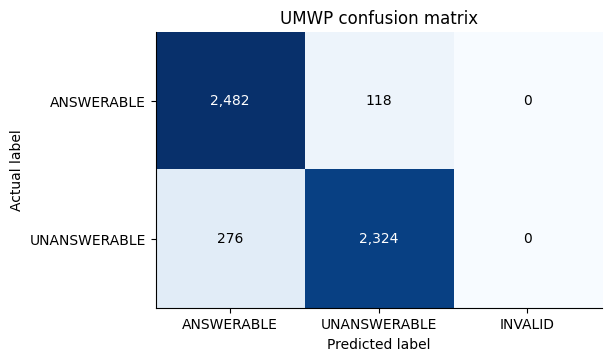

,Actual examples,Correct,Wrong label,INVALID,Wrong-label rate,Total error rate
Actual class,,,,,,
ANSWERABLE,2600,2482,118,0,4.54%,4.54%
UNANSWERABLE,2600,2324,276,0,10.62%,10.62%


There were **118 false positives** (4.54% of answerable questions) and **276 false negatives** (10.62% of unanswerable questions). Of the true UNANSWERABLE rows, 0 additionally received INVALID responses and count as missed positives in recall.

,Row index,Question ID,Question,Actual label,Prediction,Raw response (repr),Hit token limit
Error type,,,,,,,
False positive,18,19,Matthew gave equal numbers of crackers and cak...,ANSWERABLE,UNANSWERABLE,'UNANSWERABLE',False
False negative,2609,2510,Bobby ate -23 pieces of candy. If he initially...,UNANSWERABLE,ANSWERABLE,'ANSWERABLE',False


**Categories with no recorded examples:** INVALID.

In [5]:
show_evaluation('UMWP', umwp_metrics, umwp_matrix)
show_class_errors(umwp_matrix)
display(Markdown(interpret_errors(umwp_matrix)))
show_examples(umwp_predictions, 'id')


## 5. MATE Results & Analysis

MATE is the second external benchmark. This section uses the complete saved run and the same error-example selection rule.

,Examples,Accuracy,Precision (UNANSWERABLE),Recall (UNANSWERABLE),F1 (UNANSWERABLE),Invalid outputs
Dataset,,,,,,
MATE,"9,586",85.43%,92.54%,77.07%,84.10%,0 (0.00%)


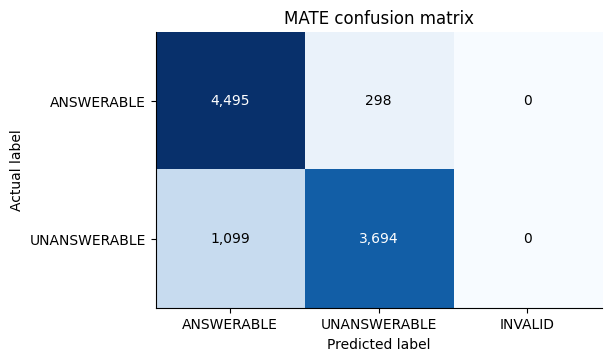

,Actual examples,Correct,Wrong label,INVALID,Wrong-label rate,Total error rate
Actual class,,,,,,
ANSWERABLE,4793,4495,298,0,6.22%,6.22%
UNANSWERABLE,4793,3694,1099,0,22.93%,22.93%


There were **298 false positives** (6.22% of answerable questions) and **1,099 false negatives** (22.93% of unanswerable questions). Of the true UNANSWERABLE rows, 0 additionally received INVALID responses and count as missed positives in recall.

,Row index,Question ID,Question,Actual label,Prediction,Raw response (repr),Hit token limit
Error type,,,,,,,
False positive,78,79,A wild tiger escapes the zoo. He escapes at 1...,ANSWERABLE,UNANSWERABLE,'UNANSWERABLE',False
False negative,81,82,Find either the middle or the greatest number ...,UNANSWERABLE,ANSWERABLE,'ANSWERABLE',False


**Categories with no recorded examples:** INVALID.

In [6]:
show_evaluation('MATE', mate_metrics, mate_matrix)
show_class_errors(mate_matrix)
display(Markdown(interpret_errors(mate_matrix)))
show_examples(mate_predictions, 'id')


## 6. Dataset Comparison & Interpretation

Rates use each dataset's full run as the denominator for accuracy, INVALID rate, and prediction shares. Precision, recall and F1 use the UNANSWERABLE class. The metric chart shows INVALID separately because its scale is much smaller.

,ANSWERABLE,UNANSWERABLE,INVALID
Dataset,,,
SUM Test,6126 (55.98%),4818 (44.02%),0 (0.00%)
UMWP,2758 (53.04%),2442 (46.96%),0 (0.00%)
MATE,5594 (58.36%),3992 (41.64%),0 (0.00%)


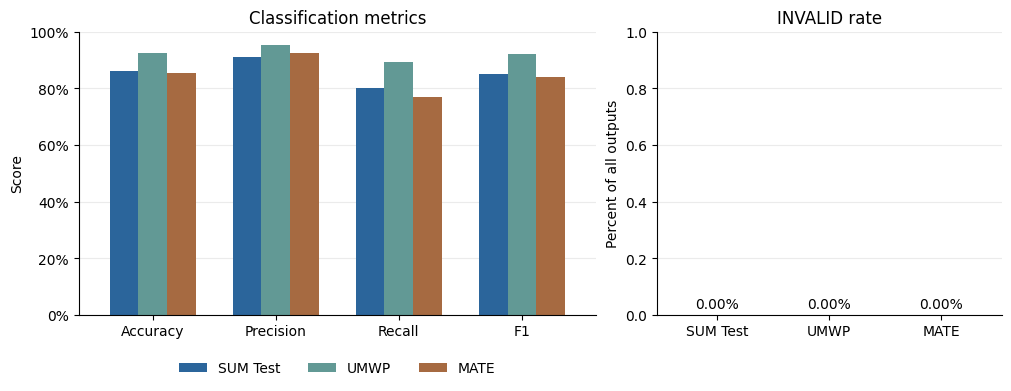

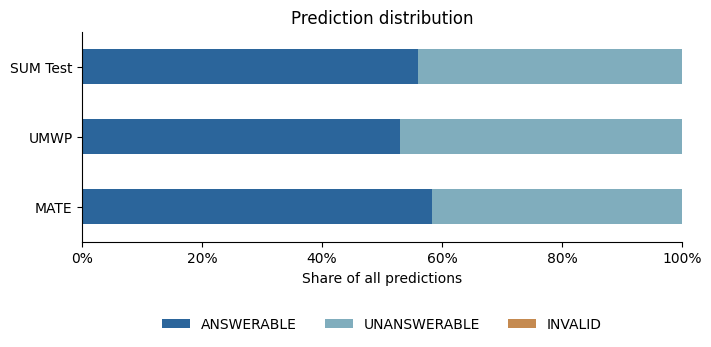

In [7]:
evaluations = {'SUM Test': (sum_metrics, sum_matrix), 'UMWP': (umwp_metrics, umwp_matrix), 'MATE': (mate_metrics, mate_matrix)}
metric_rates = pd.DataFrame({
    name: {label: metrics[key] for label, key in METRICS.items()}
    for name, (metrics, _) in evaluations.items()
})
metric_rates.index = ['Accuracy', 'Precision', 'Recall', 'F1']
invalid_rates = pd.Series({name: metrics['invalid_rate'] for name, (metrics, _) in evaluations.items()})
prediction_counts = pd.DataFrame({
    name: matrix.sum(axis=0) for name, (_, matrix) in evaluations.items()
}).T
prediction_shares = prediction_counts.div(prediction_counts.sum(axis=1), axis=0)
display((prediction_counts.astype(str) + ' (' + prediction_shares.map('{:.2%}'.format) + ')')
        .rename_axis('Dataset'))

colors = ['#2b659b', '#629995', '#a66a41']
fig, (ax_metrics, ax_invalid) = plt.subplots(
    1, 2, figsize=(10, 3.8), width_ratios=[3, 2], layout='constrained',
)
metric_rates.plot.bar(ax=ax_metrics, color=colors, rot=0, width=0.7)
ax_metrics.set(ylim=(0, 1), ylabel='Score', title='Classification metrics')
ax_metrics.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(xmax=1))
ax_metrics.legend(frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=3)
invalid_bars = ax_invalid.bar(invalid_rates.index, invalid_rates * 100, color=colors)
ax_invalid.bar_label(invalid_bars, labels=[f'{rate:.2%}' for rate in invalid_rates], padding=3)
ax_invalid.set(ylim=(0, 1), ylabel='Percent of all outputs', title='INVALID rate')
for ax in (ax_metrics, ax_invalid):
    ax.set_axisbelow(True)
    ax.grid(axis='y', alpha=0.25)
plt.show()
plt.close(fig)

fig, ax = plt.subplots(figsize=(7, 3.3), layout='constrained')
prediction_shares.plot.barh(ax=ax, stacked=True, color=['#2b659b', '#80adbd', '#c58a50'])
ax.invert_yaxis()
ax.set(xlim=(0, 1), xlabel='Share of all predictions', ylabel='', title='Prediction distribution')
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(xmax=1))
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.3), ncol=3, frameon=False)
plt.show()
plt.close(fig)

In [8]:
observations = []
for target, reference in [('UMWP', 'SUM Test'), ('MATE', 'SUM Test'), ('MATE', 'UMWP')]:
    observed, baseline = evaluations[target][0], evaluations[reference][0]
    gaps = {name: (observed[key] - baseline[key]) * 100 for name, key in METRICS.items()}
    observations.append(
        f"- **{target} versus {reference}**: accuracy {gaps['Accuracy']:+.2f}, "
        f"UNANSWERABLE precision {gaps['Precision (UNANSWERABLE)']:+.2f}, recall "
        f"{gaps['Recall (UNANSWERABLE)']:+.2f}, and F1 {gaps['F1 (UNANSWERABLE)']:+.2f} "
        "percentage points."
    )
display(Markdown("\n".join(observations)))
display(Markdown(
    "The external datasets differ in measured performance under the same saved protocol. "
    "The results do not establish a cause for the difference."
))

- **UMWP versus SUM Test**: accuracy +6.39, UNANSWERABLE precision +4.24, recall +9.32, and F1 +7.04 percentage points.
- **MATE versus SUM Test**: accuracy -0.61, UNANSWERABLE precision +1.61, recall -2.99, and F1 -1.05 percentage points.
- **MATE versus UMWP**: accuracy -7.00, UNANSWERABLE precision -2.63, recall -12.31, and F1 -8.09 percentage points.

The external datasets differ in measured performance under the same saved protocol. The results do not establish a cause for the difference.

## 7. API Token Usage & Estimated Cost

The estimates use reported usage from completed responses and the archived per-token rates. Actual provider billing may include usage that the client did not receive.

In [9]:
usage = pd.DataFrame.from_dict({
    name: {
        'Requests': record['usage']['completed_requests'],
        'Attempts': record['usage']['request_attempts'],
        'Pending attempts': record['usage']['attempts_by_state'].get('pending', 0),
        'Input tokens': record['usage']['input_tokens'],
        'Cached input tokens': record['usage']['cached_input_tokens'],
        'Output tokens': record['usage']['output_tokens'],
        'Total tokens': record['usage']['total_tokens'],
        'Responses missing usage': record['usage']['responses_without_usage'],
        'Estimated cost (USD)': record['usage']['estimated_cost_usd'],
    }
    for name, record in metadata.items()
}, orient='index').rename_axis('Dataset')

combined = usage.sum(axis=0, skipna=False)
summary = pd.concat([usage, combined.to_frame().T.rename(index={0: 'Combined'})]).rename_axis('Dataset')
summary['Estimated cost (USD)'] = summary['Estimated cost (USD)'].map(
    lambda cost: f'${cost:.6f}' if pd.notna(cost) else 'Unavailable',
)
for column in summary.columns.drop('Estimated cost (USD)'):
    summary[column] = summary[column].map('{:,.0f}'.format)
display(summary)

prices = run['prices_usd_per_million']
display(Markdown(
    f'**Recorded rates ({run["pricing_verified_date"]}, USD per million tokens).** '
    f'Input ${prices["input"]:.2f}, cached input ${prices["cached_input"]:.2f}, '
    f'output ${prices["output"]:.2f}.'
))

mate_usage = mate_metadata['usage']
display(Markdown(
    f"**MATE checkpoint recovery.** After the reported network disconnection, the run resumed "
    f"with the original checkpoint and `--retry-uncertain`. The local SQLite audit found a "
    f"pending attempt and a later completed attempt for zero-based row 8825 (MATE ID 8826). "
    f"The final export contains {mate_usage['completed_requests']:,} responses from "
    f"{mate_usage['request_attempts']:,} attempts. The original pending attempt remains in the "
    "history because its provider-side outcome is unknown. It may have been billed. No token "
    "usage is available for that attempt, so the estimate excludes any such charge."
))

,Requests,Attempts,Pending attempts,Input tokens,Cached input tokens,Output tokens,Total tokens,Responses missing usage,Estimated cost (USD)
Dataset,,,,,,,,,
SUM Test,"10,944","10,944",0,"1,241,573",0,"59,538","1,301,111",0,$1.539263
UMWP,"5,200","5,200",0,"506,868",0,"28,442","535,310",0,$0.649078
MATE,"9,586","9,587",1,"918,655",0,"51,922","970,577",0,$1.178265
Combined,"25,730","25,731",1,"2,667,096",0,"139,902","2,806,998",0,$3.366606


**Recorded rates (2026-11-22, USD per million tokens).** Input $1.00, cached input $0.05, output $5.00.

**MATE checkpoint recovery.** After the reported network disconnection, the run resumed with the original checkpoint and `--retry-uncertain`. The local SQLite audit found a pending attempt and a later completed attempt for zero-based row 8825 (MATE ID 8826). The final export contains 9,586 responses from 9,587 attempts. The original pending attempt remains in the history because its provider-side outcome is unknown. It may have been billed. No token usage is available for that attempt, so the estimate excludes any such charge.

## 8. Conclusion

In [10]:
scores = "; ".join(
    f"{name} {metrics['f1_unanswerable']:.2%}" for name, (metrics, _) in evaluations.items()
)
invalid = sum(metrics['num_invalid'] for metrics, _ in evaluations.values())
display(Markdown(
    f"UNANSWERABLE F1 was **{scores}**. The three strict runs produced "
    f"**{invalid:,} INVALID responses**. MATE completed after checkpoint recovery, "
    "and the usage estimate reflects responses with recorded provider token counts."
))

UNANSWERABLE F1 was **SUM Test 85.15%; UMWP 92.19%; MATE 84.10%**. The three strict runs produced **0 INVALID responses**. MATE completed after checkpoint recovery, and the usage estimate reflects responses with recorded provider token counts.